# 06 - Regression: Gradient Boosting (XGBoost)

**Class of model:** complex, performant model (class iii in the project rubric).

**How gradient boosting works (the short version):** start with a constant prediction (the training mean, i.e. the NullModel). Then repeatedly fit a *small decision tree to the current residuals* and add a shrunken copy of it to the prediction. Each tree corrects what the previous ones got wrong. Key knobs:

| Hyperparameter | Meaning | Effect |
|---|---|---|
| `n_estimators` | number of trees | more = fits training data harder |
| `learning_rate` | shrink factor per tree | small = slower, usually generalizes better |
| `max_depth` | tree depth | deeper = captures interactions but overfits |
| `min_child_weight` | min samples-ish per leaf | larger = more conservative |
| `subsample`, `colsample_bytree` | row / column sampling per tree | adds randomness, reduces overfit |
| `reg_lambda`, `reg_alpha` | L2 / L1 penalty on leaf values | shrink toward the mean |

**Why it suits this data:** handles nonlinear effects and interactions (e.g. down x distance) automatically, needs no scaling, handles missing values natively (our `prev_*` columns), and is robust to the binary flags.

**Why we must be careful:** only ~1,400 training plays and very weak signal. A flexible model will happily memorize noise, so we (1) tune with **cross-validation grouped by game**, (2) use heavy regularization, (3) always compare to the NullModel, and (4) touch the test set only once at the end.

In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, RandomizedSearchCV
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"; TAB = ROOT / "reports" / "tables"
SEED = 42

# consistent colors across all regression figures
COLORS = {"NullModel": "tab:gray", "Linear": "tab:blue", "XGBoost": "tab:green", "NeuralNet": "tab:purple", "actual": "black"}

df = pd.read_csv(ROOT / "data" / "processed" / "model_df.csv").dropna(subset=["ppa"])
fl = json.load(open(ROOT / "data" / "processed" / "regression_feature_lists_after_eda.json"))
FEATURES, TARGET = fl["regression"]["features"], "ppa"
train, test = df[df.split == "train"].reset_index(drop=True), df[df.split == "test"].reset_index(drop=True)
Xtr, ytr, gtr = train[FEATURES], train[TARGET], train["gameId"]
Xte, yte = test[FEATURES], test[TARGET]
print(Xtr.shape, Xte.shape, "train games:", gtr.nunique())

def qof(y, p):
    return {"R2": r2_score(y, p), "MAE": mean_absolute_error(y, p), "RMSE": np.sqrt(mean_squared_error(y, p))}

(1394, 24) (378, 24) train games: 20


**Categoricals:** `down` (1-4) and `period` (1-4) are ordered, so trees can use them directly as numbers (a tree can split `down <= 2` or `down == 3` by two splits). No one-hot encoding is needed for XGBoost - this is different from the neural net later.

## 1. Baseline and an untuned model

In [2]:
null = DummyRegressor(strategy="mean").fit(Xtr, ytr)

default = XGBRegressor(random_state=SEED, n_jobs=1).fit(Xtr, ytr)   # library defaults
rows = []
for name, m in [("NullModel", null), ("XGBoost (defaults)", default)]:
    for sp, X, y in [("train", Xtr, ytr), ("test", Xte, yte)]:
        rows.append({"model": name, "split": sp, **qof(y, m.predict(X))})
pd.DataFrame(rows).round(4)

,model,split,R2,MAE,RMSE
0,NullModel,train,0.0000,0.9652,1.3460
1,NullModel,test,-0.0010,0.9356,1.2841
2,XGBoost (defaults),train,0.9825,0.1211,0.1783
3,XGBoost (defaults),test,-0.1072,1.0094,1.3505


**Reading this:** an untuned boosted model gets a near-perfect train R² but a *negative* test R² - classic overfitting. It has learned noise specific to the training games. Tuning is about reining that in.

## 2. Tuning with grouped cross-validation
`GroupKFold` keeps every play from a game in the same fold, so each validation fold is made of *unseen games* - which mirrors how the test set works. With 20 training games we use 5 folds (4 games each). The scoring metric is negative RMSE, the same metric we will report.

We search shallow, slow, heavily regularized models, and also compare the usual squared-error loss with a **pseudo-Huber** loss, which is less swayed by the extreme turnover/touchdown plays.

In [3]:
cv = GroupKFold(n_splits=5)
param_dist = {
    "n_estimators":     [50, 100, 200, 400],
    "learning_rate":    [0.01, 0.02, 0.05, 0.1],
    "max_depth":        [1, 2, 3, 4],
    "min_child_weight": [5, 10, 20, 40],
    "subsample":        [0.5, 0.7, 0.9],
    "colsample_bytree": [0.5, 0.7, 0.9],
    "reg_lambda":       [1, 5, 20, 50],
    "reg_alpha":        [0, 0.5, 2],
}
results = {}
for objective in ["reg:squarederror", "reg:pseudohubererror"]:
    base = XGBRegressor(objective=objective, random_state=SEED, n_jobs=1)
    if objective == "reg:pseudohubererror":
        base.set_params(base_score=float(ytr.median()))
    search = RandomizedSearchCV(base, param_dist, n_iter=60, scoring="neg_root_mean_squared_error",
                                cv=cv, random_state=SEED, n_jobs=-1, refit=True)
    search.fit(Xtr, ytr, groups=gtr)
    results[objective] = search
    print(f"{objective:24s} CV RMSE = {-search.best_score_:.4f}")
    print("   ", search.best_params_)

# CV RMSE of the NullModel under the SAME folds, for a fair comparison
null_cv = []
for tr_i, va_i in cv.split(Xtr, ytr, gtr):
    null_cv.append(np.sqrt(np.mean((ytr.iloc[va_i] - ytr.iloc[tr_i].mean()) ** 2)))
print(f"{'NullModel':24s} CV RMSE = {np.mean(null_cv):.4f}")

reg:squarederror         CV RMSE = 1.3396
    {'subsample': 0.7, 'reg_lambda': 20, 'reg_alpha': 0, 'n_estimators': 100, 'min_child_weight': 10, 'max_depth': 3, 'learning_rate': 0.01, 'colsample_bytree': 0.7}


reg:pseudohubererror     CV RMSE = 1.3348
    {'subsample': 0.7, 'reg_lambda': 50, 'reg_alpha': 2, 'n_estimators': 200, 'min_child_weight': 20, 'max_depth': 4, 'learning_rate': 0.02, 'colsample_bytree': 0.5}
NullModel                CV RMSE = 1.3464


**How to read it:** if the tuned CV RMSE is only barely below the NullModel's CV RMSE, that is the honest picture of how much signal there is. We pick the objective with the lower CV RMSE - *chosen on training games only*.

In [4]:
best_obj = min(results, key=lambda k: -results[k].best_score_)
best = results[best_obj].best_estimator_
print("Selected objective:", best_obj)
print(results[best_obj].best_params_)

cvres = pd.DataFrame(results[best_obj].cv_results_).sort_values("rank_test_score")
cvres[["rank_test_score", "mean_test_score", "std_test_score"] + [c for c in cvres if c.startswith("param_")]].head(8).round(4)

Selected objective: reg:pseudohubererror
{'subsample': 0.7, 'reg_lambda': 50, 'reg_alpha': 2, 'n_estimators': 200, 'min_child_weight': 20, 'max_depth': 4, 'learning_rate': 0.02, 'colsample_bytree': 0.5}


,rank_test_score,mean_test_score,std_test_score,param_subsample,param_reg_lambda,param_reg_alpha,param_n_estimators,param_min_child_weight,param_max_depth,param_learning_rate,param_colsample_bytree
10,1,-1.3348,0.0733,0.7,50,2.0,200,20,4,0.02,0.5
2,2,-1.3359,0.0739,0.9,20,2.0,400,10,2,0.01,0.5
59,3,-1.3360,0.0768,0.5,1,0.0,200,5,4,0.01,0.7
51,4,-1.3362,0.0803,0.5,20,2.0,200,5,2,0.05,0.7
44,5,-1.3363,0.0773,0.7,20,0.0,400,5,3,0.01,0.5
43,6,-1.3364,0.0722,0.7,50,2.0,100,40,2,0.05,0.9
4,7,-1.3366,0.0765,0.9,50,0.0,400,10,2,0.02,0.9
53,8,-1.3369,0.0763,0.7,20,0.0,400,10,3,0.01,0.7


## 3. Test-set evaluation (touched once)

In [5]:
pred_tr, pred_te = best.predict(Xtr), best.predict(Xte)
final = pd.DataFrame([
    {"model": "NullModel", "split": "train", **qof(ytr, null.predict(Xtr))},
    {"model": "NullModel", "split": "test",  **qof(yte, null.predict(Xte))},
    {"model": "XGBoost (tuned)", "split": "train", **qof(ytr, pred_tr)},
    {"model": "XGBoost (tuned)", "split": "test",  **qof(yte, pred_te)},
])
final.to_csv(TAB / "regression_results_xgboost.csv", index=False)
final.round(4)

,model,split,R2,MAE,RMSE
0,NullModel,train,0.0000,0.9652,1.3460
1,NullModel,test,-0.0010,0.9356,1.2841
2,XGBoost (tuned),train,0.0872,0.8917,1.2860
3,XGBoost (tuned),test,0.0345,0.8846,1.2612


### How stable is that test number?
The test set is only 6 games / 378 plays, so one R² value can be lucky or unlucky. Two checks:
1. **Seed spread:** refit the same configuration with 10 random seeds (row/column subsampling changes the model slightly).
2. **Bootstrap by game:** resample the 6 test games with replacement and recompute the *improvement over the NullModel* in RMSE. If the interval comfortably includes 0, we cannot claim the model beats the baseline.

In [6]:
seed_rows = []
for s in range(10):
    m = XGBRegressor(**{**best.get_params(), "random_state": s}).fit(Xtr, ytr)
    seed_rows.append(qof(yte, m.predict(Xte)))
seeds = pd.DataFrame(seed_rows)
print("Test metrics over 10 seeds (mean +/- std):")
print(seeds.agg(["mean", "std"]).round(4))

rng = np.random.default_rng(SEED)
games = test["gameId"].unique()
null_pred = null.predict(Xte)
gains = []
for _ in range(2000):
    pick = rng.choice(games, size=len(games), replace=True)
    idx = np.concatenate([np.where(test["gameId"].values == g)[0] for g in pick])
    r_null = np.sqrt(np.mean((yte.values[idx] - null_pred[idx]) ** 2))
    r_mod = np.sqrt(np.mean((yte.values[idx] - pred_te[idx]) ** 2))
    gains.append(r_null - r_mod)
lo, hi = np.percentile(gains, [2.5, 97.5])
print(f"\nRMSE improvement over NullModel: {np.mean(gains):+.4f}  (95% bootstrap-by-game CI: {lo:+.4f} to {hi:+.4f})")

Test metrics over 10 seeds (mean +/- std):
          R2     MAE    RMSE
mean  0.0326  0.8859  1.2625
std   0.0028  0.0014  0.0018



RMSE improvement over NullModel: +0.0241  (95% bootstrap-by-game CI: -0.0129 to +0.0662)


## 4. Diagnostics plots

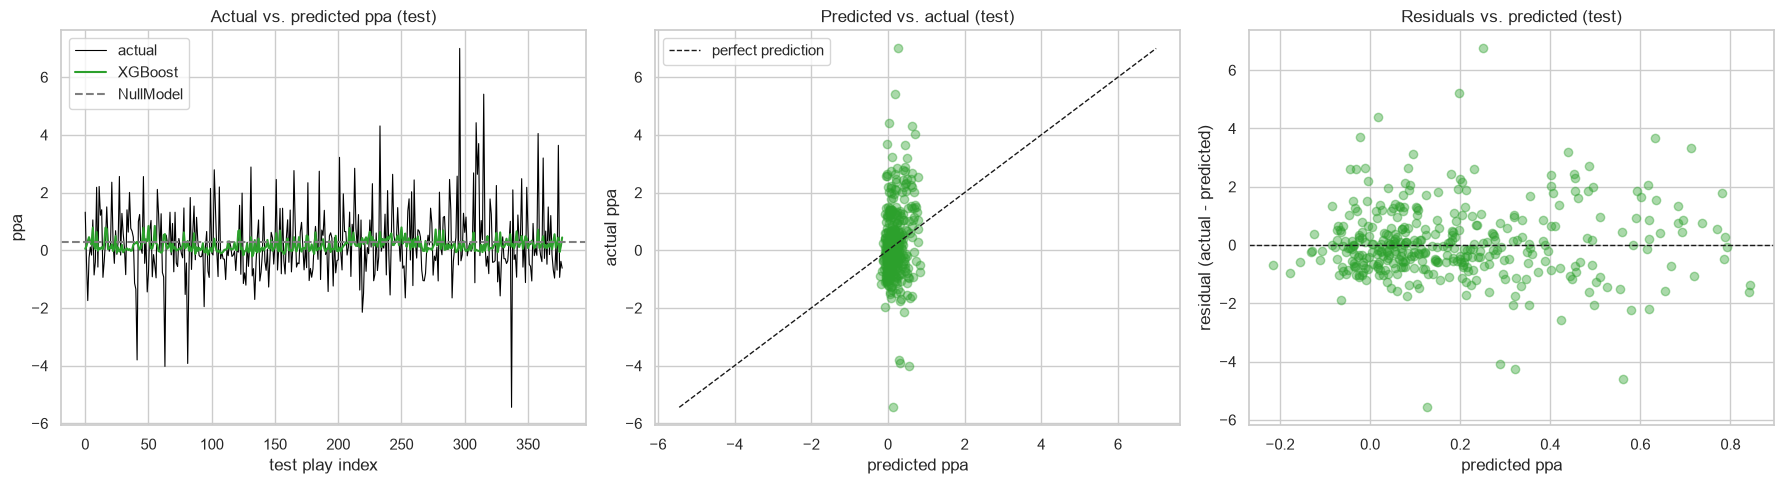

range of predictions: -0.215 to 0.844 | range of actual: -5.44 to 7.0


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# (a) predicted vs. actual over the test plays (the "index" plot the assignment asks for)
ax[0].plot(yte.values, color=COLORS["actual"], lw=0.8, label="actual")
ax[0].plot(pred_te, color=COLORS["XGBoost"], lw=1.5, label="XGBoost")
ax[0].axhline(null.constant_.item(), color=COLORS["NullModel"], ls="--", label="NullModel")
ax[0].set_xlabel("test play index"); ax[0].set_ylabel("ppa"); ax[0].legend(); ax[0].set_title("Actual vs. predicted ppa (test)")

# (b) scatter predicted vs actual
ax[1].scatter(pred_te, yte, alpha=0.4, color=COLORS["XGBoost"])
lim = [yte.min(), yte.max()]
ax[1].plot(lim, lim, "k--", lw=1, label="perfect prediction")
ax[1].set_xlabel("predicted ppa"); ax[1].set_ylabel("actual ppa"); ax[1].legend(); ax[1].set_title("Predicted vs. actual (test)")

# (c) residuals
res = yte - pred_te
ax[2].scatter(pred_te, res, alpha=0.4, color=COLORS["XGBoost"])
ax[2].axhline(0, color="k", ls="--", lw=1)
ax[2].set_xlabel("predicted ppa"); ax[2].set_ylabel("residual (actual - predicted)"); ax[2].set_title("Residuals vs. predicted (test)")
plt.tight_layout(); plt.savefig(FIG / "regression_xgb_diagnostics.png", dpi=150); plt.show()
print("range of predictions:", round(pred_te.min(), 3), "to", round(pred_te.max(), 3), "| range of actual:", round(yte.min(), 2), "to", round(yte.max(), 2))

**What to look for:** a model with real skill produces predictions that spread out along the diagonal in (b). If predictions are squeezed into a narrow band near the mean (as expected here), the model is only making small, cautious adjustments - which is the right behavior when the signal is weak.

## 5. Feature importance
Built-in importance (**gain**) is computed on training data and can favor features the model used to overfit. **Permutation importance** on *held-out* data is more honest: shuffle one feature and see how much test RMSE gets worse. A feature with importance ~0 or negative is not helping out-of-sample.

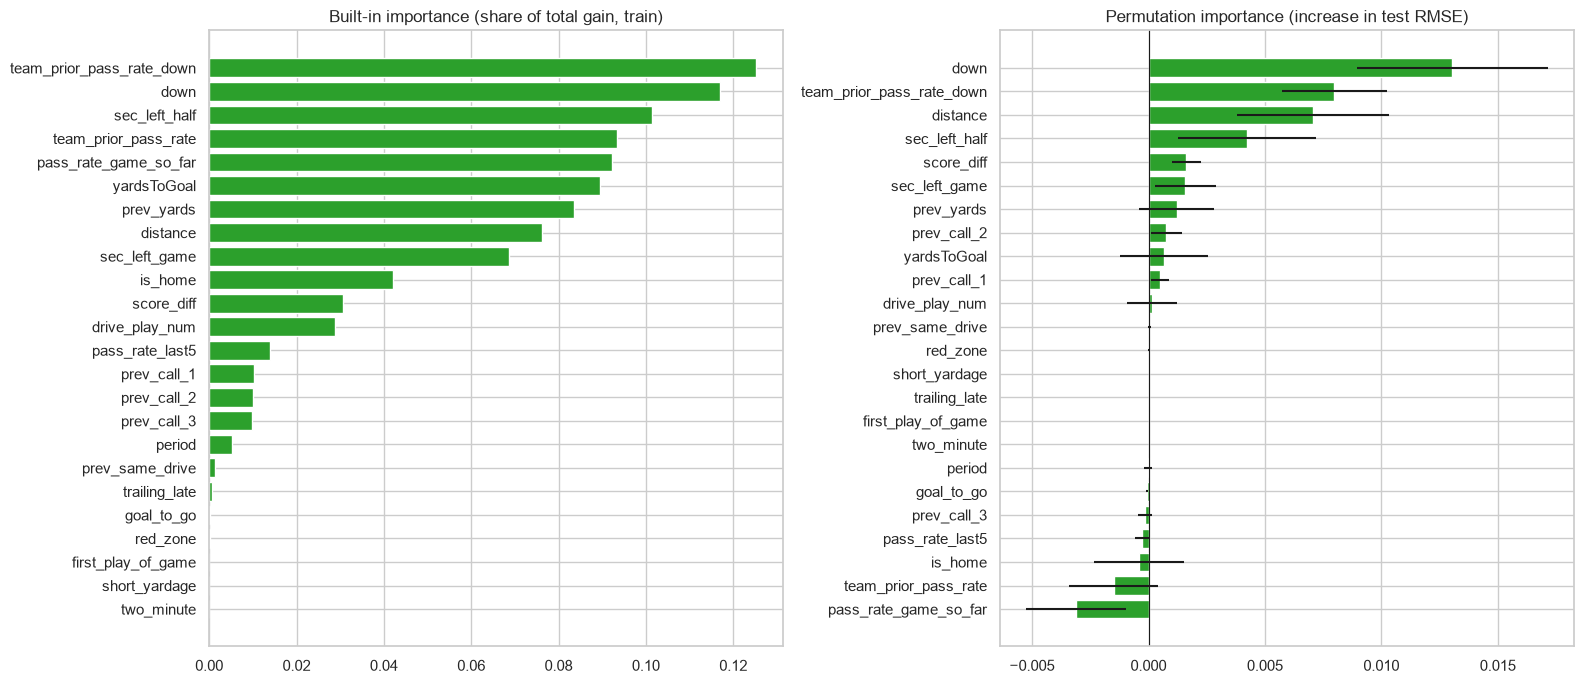

,gain_share,perm_mean,perm_std
down,0.1169,0.0131,0.0041
team_prior_pass_rate_down,0.1251,0.0080,0.0023
distance,0.0762,0.0071,0.0033
sec_left_half,0.1014,0.0042,0.0030
score_diff,0.0307,0.0016,0.0006
sec_left_game,0.0688,0.0016,0.0013
prev_yards,0.0835,0.0012,0.0016
prev_call_2,0.0100,0.0008,0.0007
yardsToGoal,0.0895,0.0007,0.0019
prev_call_1,0.0103,0.0005,0.0004


In [8]:
gain = pd.Series(best.get_booster().get_score(importance_type="total_gain")).reindex(FEATURES).fillna(0)
gain = gain / gain.sum()

perm = permutation_importance(best, Xte, yte, scoring="neg_root_mean_squared_error", n_repeats=30, random_state=SEED, n_jobs=1)
perm_df = pd.DataFrame({"gain_share": gain, "perm_mean": perm.importances_mean, "perm_std": perm.importances_std})
perm_df = perm_df.sort_values("perm_mean", ascending=False)
perm_df.round(4).to_csv(TAB / "regression_xgb_feature_importance.csv")

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
g = perm_df["gain_share"].sort_values()
ax[0].barh(g.index, g.values, color=COLORS["XGBoost"]); ax[0].set_title("Built-in importance (share of total gain, train)")
p = perm_df.sort_values("perm_mean")
ax[1].barh(p.index, p["perm_mean"], xerr=p["perm_std"], color=COLORS["XGBoost"])
ax[1].axvline(0, color="k", lw=0.8); ax[1].set_title("Permutation importance (increase in test RMSE)")
plt.tight_layout(); plt.savefig(FIG / "regression_xgb_feature_importance.png", dpi=150); plt.show()
perm_df.round(4).head(10)

## 6. Partial dependence of the top features
Shows the *average* model prediction as one feature varies - the boosted-tree equivalent of a regression coefficient, but allowed to be curved.

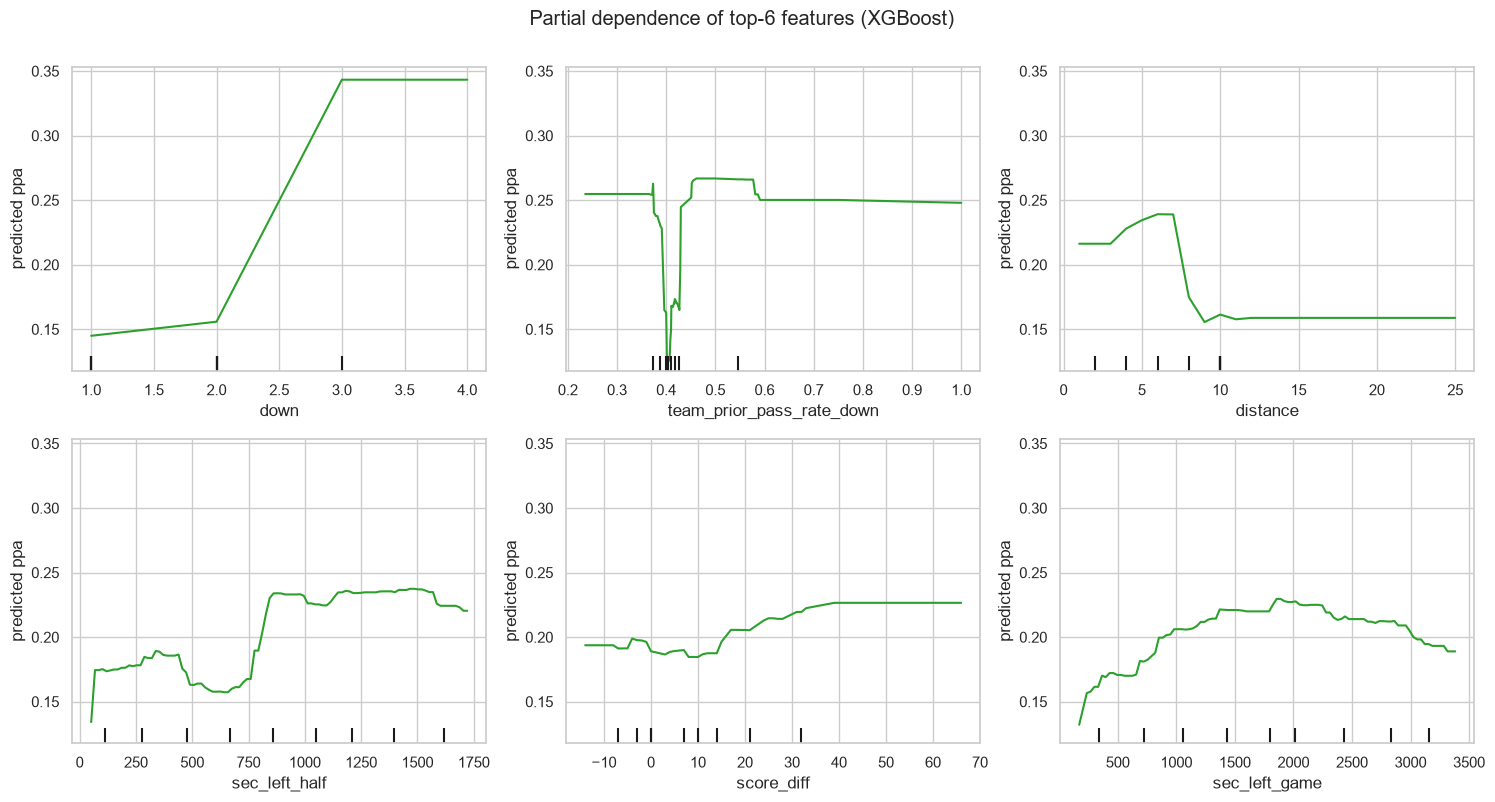

In [9]:
from sklearn.inspection import PartialDependenceDisplay
top = list(perm_df.index[:6])
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
PartialDependenceDisplay.from_estimator(best, Xtr.astype(float), top, ax=ax.ravel(), line_kw={"color": COLORS["XGBoost"]})
for a in ax.ravel(): a.set_ylabel("predicted ppa")
plt.suptitle("Partial dependence of top-6 features (XGBoost)", y=1.0)
plt.tight_layout(); plt.savefig(FIG / "regression_xgb_partial_dependence.png", dpi=150); plt.show()

## Summary (fill in after reading the results above)
See the numbers printed in sections 1, 2, 3 and 5. The key questions to answer in the report:
1. Does tuned XGBoost beat the NullModel on CV *and* on test? By how much, and is the bootstrap interval above 0?
2. Which features matter out-of-sample (permutation importance), and do they agree with the EDA (`down`, `score_diff`, `is_home`)?
3. Is the gap between train and test still large (overfitting)?